# 04 - Evaluating the app's scorer

Notebooks 02 and 03 built the anomaly idea on wearable data. The app is different: people type in **spot readings** (blood pressure, heart rate, temperature, SpO2...), not daily Fitbit summaries. So we could not drop the Isolation Forest straight into the app. Instead we ported the *method* into the backend (`backend/app/services/scoring.py`):

- new users are compared with **published normal ranges** (the "global" part)
- each vital gets a **personal baseline** (median + MAD of their last 30 readings)
- per vital, the weight moves from published to personal between **7 and 21** readings
- **safety limits** (fever 38 °C, SpO2 92 %, systolic 160...) always flag
- a value that is in the normal range but unusual **for that person** needs a **second unusual reading in a row** (the idea from notebook 03)
- a vital only counts once its contribution passes `FLAG_THRESHOLD`

This notebook tests **that exact file**: we import it from the backend, we don't copy it, so the numbers here are the numbers of the real app.

**Data.** LifeSnaps has no blood pressure or SpO2, but two signals match app vitals: resting heart rate → `heart_rate`, and sleeping breathing rate → `respiratory_rate`. We treat each day as one reading. That's a simplification: a resting HR is calmer than a random spot reading, so real app readings will be noisier.

In [1]:
import sys, uuid, json
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('..')
sys.path.append('../../backend')          # the app's own scorer
import app.services.scoring as S
from healthnexus_ml.preprocessing import PROCESSED_DIR

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.figsize'] = (9, 3.6)
print('model:', S.MODEL_VERSION, '| threshold', S.FLAG_THRESHOLD, '| baseline', S.MIN_BASELINE_READINGS, '->', S.FULL_BASELINE_READINGS)

model: personal-baseline-v1 | threshold 0.5 | baseline 7 -> 21


## 1. Turn the daily data into app readings

In [2]:
df = pd.read_csv(PROCESSED_DIR / 'daily_clean.csv', parse_dates=['date']).sort_values(['user_id', 'date'])
df = df.rename(columns={'resting_hr': 'heart_rate', 'breathing_rate': 'respiratory_rate'})

def to_readings(g):
    out = []
    for hr, rr in zip(g['heart_rate'], g['respiratory_rate']):
        v = {}
        if not np.isnan(hr): v['heart_rate'] = round(float(hr), 1)
        if not np.isnan(rr): v['respiratory_rate'] = round(float(rr), 1)
        out.append(v)
    return out

seqs = {u: [v for v in to_readings(g) if v] for u, g in df.groupby('user_id')}
print(len(seqs), 'people,', sum(map(len, seqs.values())), 'readings')
pd.Series({k: sum(k in v for s in seqs.values() for v in s) for k in ['heart_rate', 'respiratory_rate']}, name='readings with it')

71 people, 4432 readings


heart_rate          4422
respiratory_rate    2408
Name: readings with it, dtype: int64

Two scorers to compare:
- **old**: the placeholder the app had before: flag anything outside the published normal range
- **new**: `score_reading()` from the backend, given the person's earlier readings (max 120, like the app)

In [3]:
U = uuid.uuid4()
HISTORY = 120

def old_flag(v):
    return any(S.published_contribution(k, x) > 0 for k, x in v.items())

def run(seqs, scorer=lambda v, h: S.score_reading(U, v, h).is_anomaly):
    rows = []
    for u, seq in seqs.items():
        for i, v in enumerate(seq):
            h = seq[max(0, i - HISTORY):i]
            n = sum('heart_rate' in x for x in h)
            rows.append({'user': u, 'i': i, 'old': old_flag(v), 'new': scorer(v, h), 'stage': S.stage_of(n)})
    return pd.DataFrame(rows)

clean = run(seqs)
clean[['old', 'new']].mean().rename('share of normal days flagged').round(3)

old    0.246
new    0.015
Name: share of normal days flagged, dtype: float64

## 2. False flags on normal days

There's no illness marked in this data, so on these days a flag is (almost always) a false alarm.

In [4]:
by_stage = clean.groupby('stage')[['old', 'new']].mean().loc[['learning', 'blending', 'personal']]
by_stage.round(3)

,old,new
stage,,
learning,0.239,0.035
blending,0.245,0.008
personal,0.248,0.014


people flagged on more than half their days: old 15 | new 0


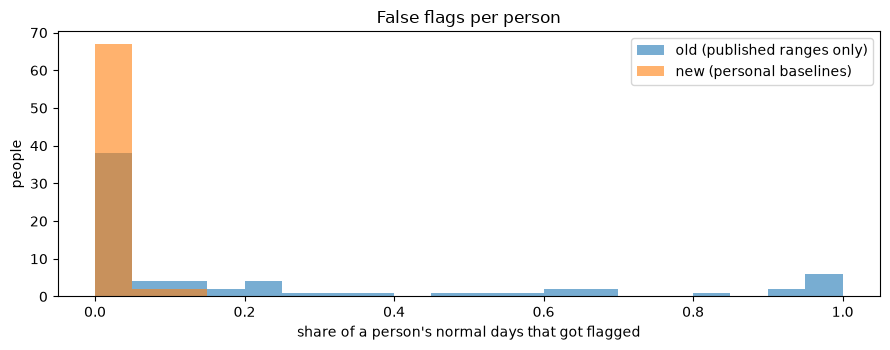

In [5]:
per_user = clean.groupby('user')[['old', 'new']].mean()
print('people flagged on more than half their days: old', (per_user.old > .5).sum(), '| new', (per_user.new > .5).sum())

bins = np.linspace(0, 1, 21)
plt.hist(per_user.old, bins=bins, alpha=.6, label='old (published ranges only)')
plt.hist(per_user.new, bins=bins, alpha=.6, label='new (personal baselines)')
plt.xlabel('share of a person\'s normal days that got flagged'); plt.ylabel('people'); plt.legend()
plt.title('False flags per person'); plt.tight_layout(); plt.savefig(FIG / 'false_flags_per_user.png', dpi=160); plt.show()

In [6]:
# who does the old scorer keep flagging? compare their usual resting HR
usual_hr = df.groupby('user_id')['heart_rate'].median()
worst = per_user.sort_values('old', ascending=False).head(8).join(usual_hr.rename('median HR'))
worst.round(2)

,old,new,median HR
user,,,
621e326767b776a24012e179,1.00,0.03,54.45
621e314867b776a24029ebf9,1.00,0.14,47.18
621e366567b776a24076a727,1.00,0.06,51.95
621e33ed67b776a2401cf5f7,1.00,0.00,55.39
621e2f7a67b776a240f14425,1.00,0.05,52.81
621e339967b776a240e502de,0.96,0.04,55.98
621e30f467b776a240f22944,0.93,0.00,58.16
621e34ff67b776a240e446d6,0.92,0.00,53.44


This is the biggest win. The old placeholder flagged **about 1 in 4 normal days**, and **15 of 71 people were flagged on more than half their days**. Looking at who: almost all have a resting HR in the low-to-mid 50s, which is healthy (fit people) but "below the 60-100 normal range". The old scorer would have flagged them every single day forever, and the PHC worker would have learned to ignore them.

The new scorer flags **1.5 %** of normal days and **nobody** more than half the time. The learning stage is a bit higher (3.5 %) because brand-new users can only be compared with published ranges, but it only counts once a value is clearly outside the band (`FLAG_THRESHOLD`), not 1 bpm outside it.

## 3. Detecting illness-like episodes

Same idea as notebook 03: pick 3 days in a row and push heart rate and breathing rate up, like the start of an infection. We do it at three strengths, and at two points in a person's history:
- **established**: after their 25th reading (baseline fully personal)
- **new user**: starting at their 4th reading (still on published ranges)

Most of these changes stay **inside** the normal range (e.g. 58 → 68 bpm), which is exactly the case published ranges can't see.

In [7]:
SEVERITY = {'mild': (6, 1.5), 'moderate': (10, 2.5), 'strong': (15, 4.0)}
rng = np.random.default_rng(7)

def pick_start(seq, after):
    ok = [i for i in range(after, len(seq) - 3) if all('heart_rate' in seq[j] for j in range(i, i + 3))]
    return int(rng.choice(ok)) if ok else None

STARTS = {timing: {u: pick_start(s, after) for u, s in seqs.items()} for timing, after in [('established', 25), ('new user', 3)]}
{t: sum(v is not None for v in s.values()) for t, s in STARTS.items()}

{'established': 62, 'new user': 68}

In [8]:
def inject(seq, start, d_hr, d_rr):
    seq = [dict(v) for v in seq]
    for j in range(start, start + 3):
        seq[j]['heart_rate'] += d_hr
        if 'respiratory_rate' in seq[j]: seq[j]['respiratory_rate'] += d_rr
    return seq

def episode_results(scorer=lambda v, h: S.score_reading(U, v, h).is_anomaly, severities=SEVERITY, timings=STARTS):
    rows = []
    for timing, starts in timings.items():
        for name, (d_hr, d_rr) in severities.items():
            for u, start in starts.items():
                if start is None: continue
                seq = inject(seqs[u], start, d_hr, d_rr)
                hits_old = [old_flag(seq[j]) for j in range(start, start + 3)]
                hits_new = [scorer(seq[j], seq[max(0, j - HISTORY):j]) for j in range(start, start + 3)]
                rows.append({'timing': timing, 'severity': name, 'user': u,
                             'old': any(hits_old), 'new': any(hits_new),
                             'new_day': (hits_new.index(True) + 1) if any(hits_new) else None})
    return pd.DataFrame(rows)

ep = episode_results()
detect = ep.groupby(['timing', 'severity'])[['old', 'new']].mean().reindex(['mild', 'moderate', 'strong'], level=1)
detect.round(2)

old   new
timing      severity            
established mild      0.19  0.16
            moderate  0.16  0.68
            strong    0.26  0.98
new user    mild      0.19  0.16
            moderate  0.18  0.57
            strong    0.29  0.88

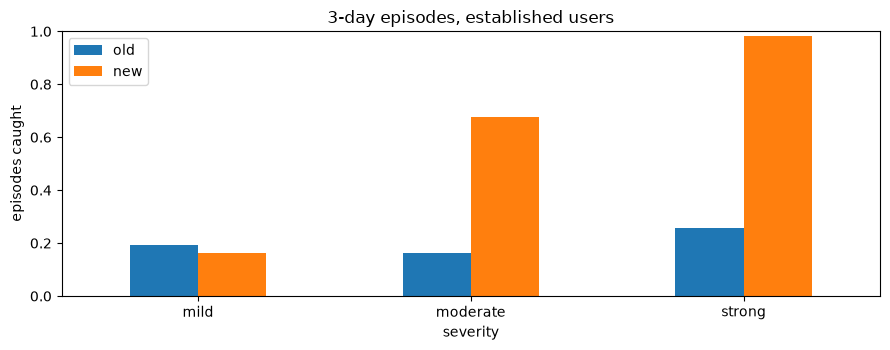

day of detection (new scorer, established):


new_day,1.0,2.0,3.0
severity,,,
mild,1,4,5
moderate,6,34,2
strong,13,48,0


In [9]:
ax = detect.loc['established'].plot.bar(rot=0)
ax.set_ylabel('episodes caught'); ax.set_ylim(0, 1); ax.set_title('3-day episodes, established users')
plt.tight_layout(); plt.savefig(FIG / 'episode_detection.png', dpi=160); plt.show()
print('day of detection (new scorer, established):')
ep[(ep.timing == 'established') & ep.new].groupby('severity')['new_day'].value_counts().unstack(fill_value=0)

For people with history, the new scorer catches **68 % of moderate** and **98 % of strong** episodes, against 16 % and 26 % for the old one. The old scorer's numbers are mostly luck: it flags those people on many normal days anyway, so some episodes happen to land on a flagged day.

Mild episodes (+6 bpm) are mostly missed (16 %). That's a change the size of normal day-to-day variation, so we accept it.

Most detections happen on **day 2** of the episode. That is the second-reading rule at work: day 1 is "unusual for you, watching", day 2 confirms it. A one-day delay felt acceptable for something that develops over days.

New users (episode starting at their 4th reading) still get **57 % / 88 %**, because breathing rate going above 20 crosses the published range even without a baseline.

## 4. Choosing FLAG_THRESHOLD

The threshold trades false flags against catching episodes. We sweep it and look at both (moderate episodes, established users).

In [10]:
def with_params(**params):
    old = {k: getattr(S, k) for k in params}
    def scorer(v, h):
        for k, val in params.items(): setattr(S, k, val)
        try:
            return S.score_reading(U, v, h).is_anomaly
        finally:
            for k, val in old.items(): setattr(S, k, val)
    return scorer

moderate = {'moderate': SEVERITY['moderate']}
established = {'established': STARTS['established']}
sweep = []
for thr in [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]:
    sc = with_params(FLAG_THRESHOLD=thr)
    sweep.append({'FLAG_THRESHOLD': thr,
                  'false flags': run(seqs, sc)['new'].mean(),
                  'moderate episodes caught': episode_results(sc, moderate, established)['new'].mean()})
sweep = pd.DataFrame(sweep).set_index('FLAG_THRESHOLD')
sweep.round(3)

,false flags,moderate episodes caught
FLAG_THRESHOLD,,
0.00,0.101,0.968
0.25,0.037,0.871
0.50,0.015,0.677
0.75,0.007,0.484
1.00,0.005,0.306
1.50,0.005,0.032


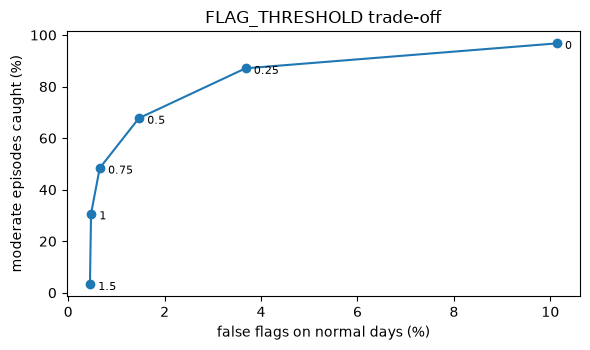

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(sweep['false flags'] * 100, sweep['moderate episodes caught'] * 100, marker='o')
for thr, r in sweep.iterrows():
    ax.annotate(f'{thr:g}', (r['false flags'] * 100, r['moderate episodes caught'] * 100), textcoords='offset points', xytext=(6, -4), fontsize=8)
ax.set_xlabel('false flags on normal days (%)'); ax.set_ylabel('moderate episodes caught (%)')
ax.set_title('FLAG_THRESHOLD trade-off'); plt.tight_layout(); plt.savefig(FIG / 'threshold_tradeoff.png', dpi=160); plt.show()

Lower thresholds catch more but flag more normal days. Below 0.5 the false-flag rate climbs fast (3.7 % at 0.25, 10 % at 0). Above 0.5 detection falls off a cliff. **0.5 is the knee of the curve**, so that's what the app uses.

## 5. Tuning the personal band together with the threshold

Our first version used `PERSONAL_OK_Z = 2.5` (a value had to be 2.5 SD from your usual before it even started to count). That caught only a small share of moderate episodes. So we tried a small grid of the two settings that matter most.

In [12]:
grid = []
for z in [1.5, 2.0, 2.5]:
    for thr in [0.25, 0.5]:
        sc = with_params(PERSONAL_OK_Z=z, FLAG_THRESHOLD=thr)
        grid.append({'PERSONAL_OK_Z': z, 'FLAG_THRESHOLD': thr,
                     'false flags': run(seqs, sc)['new'].mean(),
                     'mild': episode_results(sc, {'mild': SEVERITY['mild']}, established)['new'].mean(),
                     'moderate': episode_results(sc, moderate, established)['new'].mean(),
                     'strong': episode_results(sc, {'strong': SEVERITY['strong']}, established)['new'].mean()})
grid = pd.DataFrame(grid)
grid.round(3)

,PERSONAL_OK_Z,FLAG_THRESHOLD,false flags,mild,moderate,strong
0,1.5,0.25,0.037,0.371,0.871,1.000
1,1.5,0.50,0.015,0.161,0.677,0.984
2,2.0,0.25,0.031,0.081,0.597,0.984
3,2.0,0.50,0.010,0.032,0.452,0.968
4,2.5,0.25,0.027,0.016,0.355,0.935
5,2.5,0.50,0.009,0.016,0.161,0.758


`PERSONAL_OK_Z = 2.5` (first version) was too strict: only 16 % of moderate episodes caught. Going to **1.5** with threshold 0.5 catches **68 %** for 1.5 % false flags. In plain terms: a vital starts to count when it is 2.25 SD from the person's usual, and an in-range one has to do that twice in a row. 1.5 with threshold 0.25 catches even more (87 %), but more than doubles false flags (3.7 %), which we think is too many alerts for a health worker.

## 6. One-off spikes and the second-reading rule

LifeSnaps resting HR is a calm, once-a-day number, so it has very few one-off spikes. Real spot readings do: someone measures right after climbing stairs or after coffee. That is exactly what the "second unusual reading in a row" rule is for, so we test it on purpose: we add a one-off spike of +12 to +20 bpm to 5 % of readings and count false flags with and without the rule.

In [13]:
spike_rng = np.random.default_rng(11)
spiky = {}
for u, s in seqs.items():
    s = [dict(v) for v in s]
    for v in s:
        if 'heart_rate' in v and spike_rng.random() < 0.05:
            v['heart_rate'] += float(spike_rng.uniform(12, 20))
    spiky[u] = s

def without_confirmation(v, h):
    real = S._judge
    S._judge = lambda key, value, earlier: replace(real(key, value, earlier), confirmed=True)
    try:
        return S.score_reading(U, v, h).is_anomaly
    finally:
        S._judge = real

shipped = lambda v, h: S.score_reading(U, v, h).is_anomaly
spikes = pd.DataFrame([
    {'rule': 'with second-reading rule (shipped)', 'false flags, clean': run(seqs, shipped)['new'].mean(),
     'false flags, with spikes': run(spiky, shipped)['new'].mean(),
     'moderate caught': episode_results(shipped, moderate, established)['new'].mean()},
    {'rule': 'without it', 'false flags, clean': run(seqs, without_confirmation)['new'].mean(),
     'false flags, with spikes': run(spiky, without_confirmation)['new'].mean(),
     'moderate caught': episode_results(without_confirmation, moderate, established)['new'].mean()},
]).set_index('rule')
spikes.round(3)

,"false flags, clean","false flags, with spikes",moderate caught
rule,,,
with second-reading rule (shipped),0.015,0.015,0.677
without it,0.016,0.051,0.742


On clean data the rule hardly matters (1.5 % vs 1.6 %). With realistic one-off spikes it makes a big difference: **5.1 % false flags without it, 1.5 % with it**. That is roughly 3x fewer false alarms. The cost is a few moderate episodes (74 % → 68 %) and catching most episodes on day 2 instead of day 1. Same trade-off as the 2-day alert rule in notebook 03, and we made the same call.

## 7. Ablations: does each piece earn its place?

We switch one design choice at a time and re-run both tests (false flags on normal days, moderate episodes caught for established users).

In [14]:
VARIANTS = {
    'app model (as shipped)': lambda v, h: S.score_reading(U, v, h).is_anomaly,
    'no second-reading rule': without_confirmation,
    'personal band 2.5 SD (first version)': with_params(PERSONAL_OK_Z=2.5),
    'full baseline at 14 readings': with_params(FULL_BASELINE_READINGS=14),
    'full baseline at 30 readings': with_params(FULL_BASELINE_READINGS=30),
    'no spread floor': with_params(MIN_SPREAD={}),
    'old placeholder': lambda v, h: old_flag(v),
}
abl = []
for name, sc in VARIANTS.items():
    abl.append({'variant': name, 'false flags': run(seqs, sc)['new'].mean(),
                'moderate caught': episode_results(sc, moderate, established)['new'].mean(),
                'mild caught': episode_results(sc, {'mild': SEVERITY['mild']}, established)['new'].mean()})
abl = pd.DataFrame(abl).set_index('variant')
abl.round(3)

,false flags,moderate caught,mild caught
variant,,,
app model (as shipped),0.015,0.677,0.161
no second-reading rule,0.016,0.742,0.210
personal band 2.5 SD (first version),0.009,0.161,0.016
full baseline at 14 readings,0.014,0.677,0.161
full baseline at 30 readings,0.015,0.661,0.161
no spread floor,0.091,0.984,0.790
old placeholder,0.246,0.161,0.194


- **No spread floor** looks great on detection (98 % moderate) but false flags jump 6x (9.1 %). LifeSnaps resting HR is unusually steady, so without a floor a person's "normal" band gets so narrow that everyday noise trips it. Real spot readings are noisier than this data, so we keep the floors (4 bpm for heart rate, 5 mmHg for systolic, etc.).
- **When the baseline becomes fully personal (14, 21 or 30 readings)** barely changes anything. We kept 21 (3 weeks of daily readings) because it's a reasonable amount of history to trust.
- **2.5 SD band** is the first version: very few false flags but misses most episodes.
- The **old placeholder** is worst on false flags by far, and its "detection" is mostly chance.

## 8. Save the numbers for the report

In [15]:
metrics = {
    'model_version': S.MODEL_VERSION,
    'readings': int(len(clean)), 'people': len(seqs),
    'false_flags': clean[['old', 'new']].mean().round(4).to_dict(),
    'false_flags_by_stage': by_stage.round(4).to_dict(),
    'people_flagged_over_half': {'old': int((per_user.old > .5).sum()), 'new': int((per_user.new > .5).sum())},
    'episode_detection': {f'{t}|{s}': r.round(3).to_dict() for (t, s), r in detect.iterrows()},
    'threshold_sweep': sweep.round(4).reset_index().to_dict('records'),
    'ablations': abl.round(4).reset_index().to_dict('records'),
    'grid': grid.round(4).to_dict('records'),
    'spikes': spikes.round(4).reset_index().to_dict('records'),
}
Path('../reports').mkdir(exist_ok=True)
Path('../reports/app_scorer_metrics.json').write_text(json.dumps(metrics, indent=2))
print('saved')

saved


## Summary

| | old placeholder | new app scorer |
|---|---|---|
| false flags on normal days | 24.6 % | **1.5 %** |
| people flagged on >50 % of days | 15 of 71 | **0** |
| moderate episodes caught (established users) | 16 % | **68 %** |
| strong episodes caught | 26 % | **98 %** |

What we changed because of this notebook:
- `PERSONAL_OK_Z` 2.5 → **1.5** (section 5)
- added `FLAG_THRESHOLD = 0.5` (section 4). Without it, while the baseline is blending in, anything 1 unit outside the published band still flagged. We found this by running the demo seed: 13 of 20 healthy demo citizens got flagged
- kept the second-reading rule because of section 6

Limitations:
- only heart rate and breathing rate could be tested; blood pressure, SpO2, temperature and glucose use the same code but no real data for them
- the episodes are synthetic
- one reading per day; real users log less regularly